# Case study: HCEA differential loops

Chromatin loops are pairs of distant loci that contact each other more than
their surroundings. In single-cell Hi-C they are called per cell group, from
contacts imputed at 10 kb: scHiCluster normalises every cell's imputed matrix
by its distance background (E) and by the local background around each pixel
(T), averages them over the cells of the group, and calls pixels whose E and T
are significantly positive. This case study takes the loops that the Human Cell
Epigenome Atlas (HCEA) called this way for six blood major types and finds the
loops that differ between them, following the atlas (Fig. 4).

| Step | epione | HCEA / scHiCluster |
|---|---|---|
| call loops per group | `call_loops` (not run here) | `hicluster loop` |
| merge the groups' loops | `merge_loops` | `merged_loop` (fig4/07) |
| ANOVA of Q / E / T across groups | `loop_anova` | `compute_anova` (fig4/07) |
| statistics at each loop, differential loops | `loop_values`, `differential_loops` | fig4/07, fig4/08 |
| group-specific loops, aggregate peak analysis | `specific_loops`, `loop_apa` | fig4/07 |

## 1 · Setup

In [1]:
import os
import pathlib
import warnings
import numpy as np
import pandas as pd
warnings.filterwarnings('ignore')     # before importing epione: silences tqdm's IProgress notice
import matplotlib.pyplot as plt
import seaborn as sns
import cooler
from scipy.stats import zscore, norm

import epione as epi
from epione.single import hic

epi.pl.plot_set()

# HCEA folder with loop/majortype/ and metadata/; override with EPIONE_HCEA_DIR.
DATA = pathlib.Path(os.environ.get('EPIONE_HCEA_DIR', 'data/hcea'))
LOOPS = DATA / 'loop/majortype'
BLACKLIST = pathlib.Path(os.environ.get('EPIONE_LOOP_BLACKLIST', 'data/blacklist/hg38_bismark_loop_blacklist.bed'))
GTF = pathlib.Path(os.environ.get('EPIONE_HG38_GTF', 'data/gencode_hg38/gencode.v30.annotation.gtf'))
OUT = pathlib.Path('result/t_sc_hic_loop')
OUT.mkdir(parents=True, exist_ok=True)
NPROC = int(os.environ.get('EPIONE_NPROC', 16))

CHROMS = [f'chr{i}' for i in range(1, 23)]
L1 = pd.read_csv(DATA / 'metadata/L1color.tsv', sep='\t', index_col=0)
CODES = {'B': 'c7', 'Mast': 'c24', 'Myeloid': 'c0', 'NK': 'c27', 'Tmem': 'c1', 'Tnaive': 'c15'}
TYPES = list(CODES)
COLORS = dict(zip(TYPES, ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd', '#17becf']))
PREFIX = {t: LOOPS / c / c for t, c in CODES.items()}       # PREFIX[t].Q.cool, .Q2.cool, ...
for t in TYPES:
    assert pathlib.Path(f'{PREFIX[t]}.Q.cool').exists(), f'missing loop calls of {t}'

└─ 🔬 Starting plot initialization...
  ├─ Apply Scanpy/matplotlib settings
  ├─ Custom font setup
  ├─ Suppress warnings
  ├─ 
___________      .__                      
\_   _____/_____ |__| ____   ____   ____  
 |    __)_\____ \|  |/  _ \ /    \_/ __ \ 
 |        \  |_> >  (  <_> )   |  \  ___/ 
/_______  /   __/|__|\____/|___|  /\___  >
        \/|__|                  \/     \/ 

  ├─ 🔖 Version: 0.0.1rc1   📚 Tutorials: https://epione.readthedocs.io/
└─ ✅ plot_set complete.



## 2 · From single cells to loop calls (not run here)

The loop calls this case study starts from were made by the atlas with
scHiCluster, in two steps that epione wraps:

1. **Impute every cell at 10 kb** (`impute_cells`): convolution with a 5 x 5
   kernel (`pad=2`), random walk with restart in 30 Mb windows moved by 10 Mb,
   imputed contacts kept within 5.05 Mb of the diagonal. epione writes one
   imputed `.cool` per cell (`output='cool'`), the input of loop calling.
2. **Call loops per type** (`call_loops`, scHiCluster `hicluster loop`): each
   cell's imputed matrix is normalised by its distance background (E) and by
   the local background around each pixel (T); per type, the means over cells
   of Q (imputed contacts), E and T and of their squares are written as
   `<type>.{Q,Q2,E,E2,T,T2}.cool`. Pixels whose E and T are significantly
   positive across cells (t-tests, FDR from shuffled cells) and that stand out
   from their neighbourhood are the loop pixels (`<type>.loop.bedpe`); one
   summit per cluster of adjacent pixels is kept (`<type>.loop_summit.bedpe`).

For the 23,967 cells of the six types this takes about 1,400 CPU-hours (about
3.5 min per cell for the 10 kb imputation) and several TB of disk, so the code
below is switched off and the rest of the case study reads the atlas's
outputs (`data/hcea/loop/majortype/<type>/`). With `RUN_LOOP_CALLING = True`
it recomputes them from the contact tables and the later sections use the new
files.

In [2]:
RUN_LOOP_CALLING = False
if RUN_LOOP_CALLING:
    FASTA = pathlib.Path(os.environ.get('EPIONE_HG38_FASTA', 'data/hg38/hg38.fa'))
    sizes = pd.read_csv(f'{FASTA}.fai', sep='\t', header=None, index_col=0)[1].loc[CHROMS]
    files = {f.name.split('.3C.')[0]: f for f in sorted(DATA.glob('sc_contact/*/*.3C.contact.rmbkl.tsv.gz'))}
    meta = pd.read_csv(DATA / 'metadata/5kCG100k3C_summary.csv.gz', index_col=0)
    meta = meta.loc[meta.index.isin(list(files)) & meta['majortype'].isin(list(CODES.values()))]
    meta['celltype'] = meta['majortype'].map({c: t for t, c in CODES.items()})
    cells = list(meta.index)
    # 1. impute every cell at 10 kb; one imputed .cool per cell
    raw = hic.load_contact_tables([files[c] for c in cells], chrom_sizes=sizes, resolution=10_000,
                                  cell_ids=cells, obs=meta[['celltype']], chromosomes=CHROMS)
    hic.impute_cells(raw, out_dir=OUT / 'imputed_10kb', resolution=10_000, pad=2, std=1.0, rp=0.5, tol=0.01,
                     window_size=30_000_000, step_size=10_000_000, output_dist=5_050_000, nproc=NPROC)
    # 2. call loops per type (scHiCluster); returns {type: prefix of its Q/E/T cools and loops}
    PREFIX = hic.call_loops(raw, groupby='celltype', out_dir=OUT / 'loops', black_list=BLACKLIST,
                            shuffle=True, cpu_per_job=NPROC)
print({t: str(p) for t, p in PREFIX.items()})

{'B': 'data/hcea/loop/majortype/c7/c7', 'Mast': 'data/hcea/loop/majortype/c24/c24', 'Myeloid': 'data/hcea/loop/majortype/c0/c0', 'NK': 'data/hcea/loop/majortype/c27/c27', 'Tmem': 'data/hcea/loop/majortype/c1/c1', 'Tnaive': 'data/hcea/loop/majortype/c15/c15'}


## 3 · Loops called in each type

Each type has its loop pixels (`loop.bedpe`, 10 kb pixels that pass the
tests) and its loop summits (`loop_summit.bedpe`, one pixel per cluster of
adjacent loop pixels, the one with the highest E). `group_n_cells` is the
number of cells averaged into the type's matrices.

In [3]:
stats = {}
for t in TYPES:
    px = pd.read_csv(f'{PREFIX[t]}.loop.bedpe', sep='\t', header=None)
    sm = pd.read_csv(f'{PREFIX[t]}.loop_summit.bedpe', sep='\t', header=None)
    stats[t] = {'cells': cooler.Cooler(f'{PREFIX[t]}.Q.cool').info['group_n_cells'],
                'loop pixels': len(px), 'loop summits': len(sm),
                'median summit distance (kb)': np.median(sm[4] - sm[1]) / 1e3}
pd.DataFrame(stats).T.astype({'cells': int, 'loop pixels': int, 'loop summits': int})

,cells,loop pixels,loop summits,median summit distance (kb)
B,3513,151518,7891,240.0
Mast,1246,198036,11854,260.0
Myeloid,8306,237258,12359,270.0
NK,1073,128358,6869,210.0
Tmem,7914,136782,6835,230.0
Tnaive,1915,237036,12937,250.0


## 4 · One set of loops for all six types

`merge_loops` takes the union of the six types' loop pixels, so every type is
measured at the same positions; a column per type records which types called
each pixel.

557,196 merged loop pixels


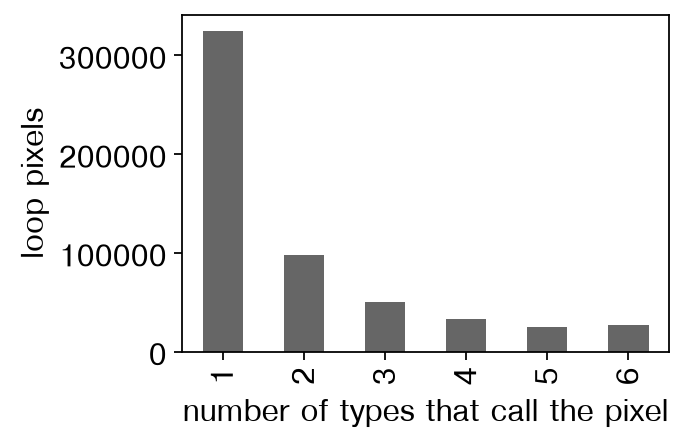

In [4]:
loops = hic.merge_loops({t: f'{PREFIX[t]}.loop.bedpe' for t in TYPES}, chromosomes=CHROMS)
n_called = loops[TYPES].sum(axis=1)
print(f'{len(loops):,} merged loop pixels')
ax = n_called.value_counts().sort_index().plot.bar(color='0.4', figsize=(4.5, 3))
ax.set_xlabel('number of types that call the pixel'); ax.set_ylabel('loop pixels')
plt.tight_layout(); plt.show()

## 5 · Which loops differ between the types?

`loop_anova` runs a one-way ANOVA at every pixel, separately for Q (imputed
contacts), E (enrichment over the distance background) and T (enrichment over
the local background). It needs only each type's mean (`Q.cool`), mean of
squares (`Q2.cool`) and number of cells: the F statistic is
`(SS_total / SS_within - 1) * (N - k) / (k - 1)`. Pixels in blacklisted regions
and outside 50 kb-5 Mb are left out, as in the atlas.

`differential_loops` reads the three F statistics at the merged loops, turns
them into p-values (F distribution, `k - 1 = 5` and `N - k` degrees of
freedom) and Benjamini-Hochberg FDRs, and applies the atlas rule: a loop is
differential when the z-scores of log10 F for both Q and T exceed
`norm.isf(0.15)` (the top ~15 % of each), it is 100 kb-4.95 Mb long and away
from the chromosome ends. We also require FDR < 0.01 for Q, E and T (atlas
Fig. 4, subtype level).

44,071 differential loop pixels of 557,196


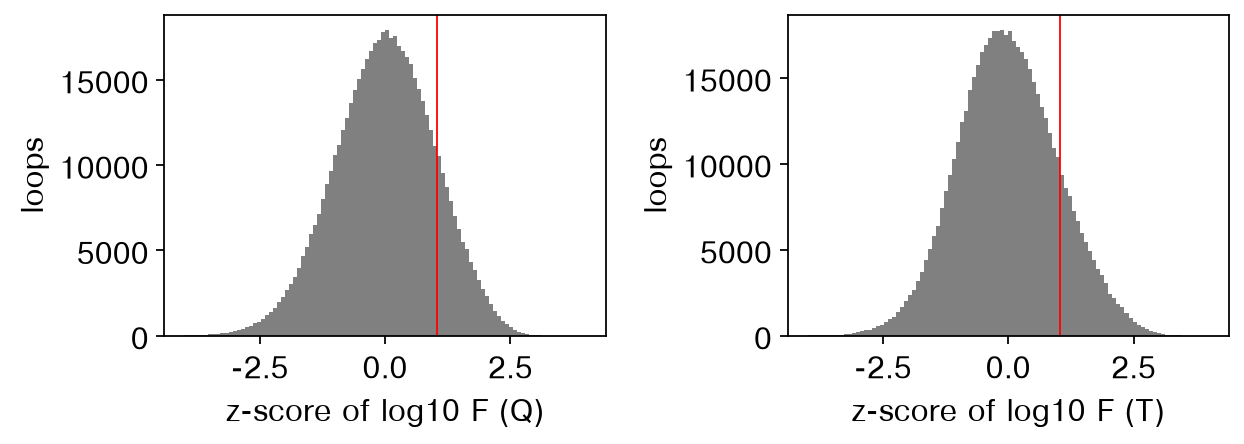

In [5]:
ANOVA = OUT / 'anova'
anova = {m: ANOVA / f'{m}pv.cool' for m in 'QET'}
if not all(p.exists() for p in anova.values()):
    anova = hic.loop_anova(PREFIX, ANOVA, chromosomes=CHROMS, black_list=BLACKLIST, nproc=NPROC)
diff = hic.differential_loops(loops, anova, fdr=0.01, nproc=NPROC)
print(f"{diff['differential'].sum():,} differential loop pixels of {len(diff):,}")

thr = norm.isf(0.15)
fig, axes = plt.subplots(1, 2, figsize=(8, 3))
for ax, m in zip(axes, 'QT'):
    v = diff.loc[diff[f'{m}anova'] > 0, f'{m}anova']
    ax.hist(zscore(np.log10(v)), bins=100, range=(-4, 4), color='0.5')
    ax.axvline(thr, color='r', lw=0.8)
    ax.set_xlabel(f'z-score of log10 F ({m})'); ax.set_ylabel('loops')
plt.tight_layout(); plt.show()

## 6 · How the differential loops differ

At the differential loops we read each type's Q and T (`loop_values`) and
z-score every loop across the six types. Clustering 2,000 random differential
loops shows blocks of loops that are strong in one type or in a few related
types.

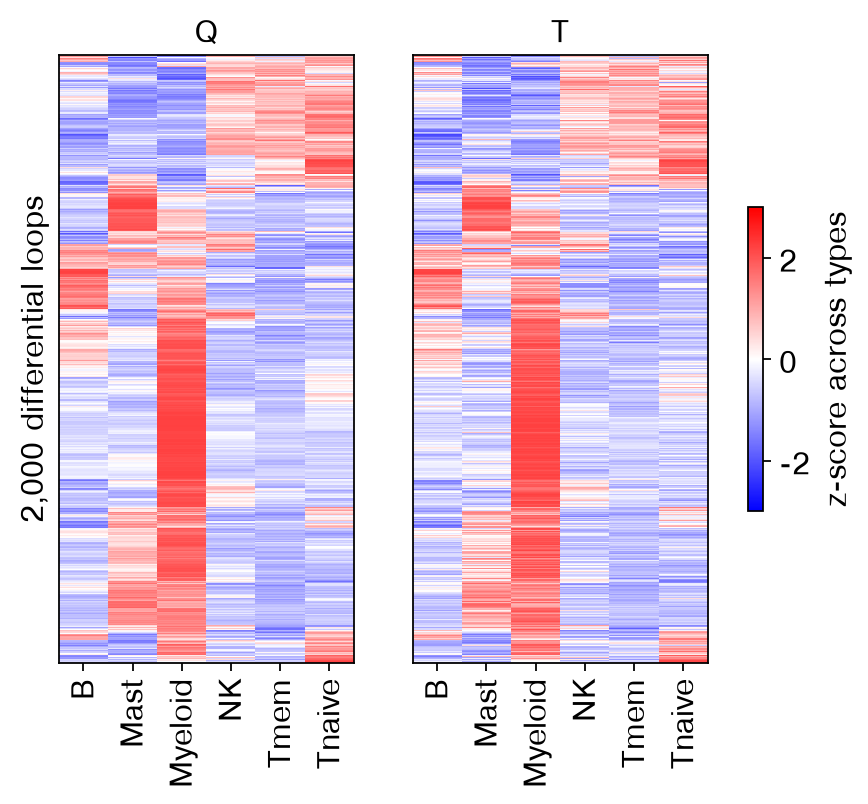

In [6]:
dl = diff.loc[diff['differential']].reset_index(drop=True)
q = hic.loop_values(dl, {t: f'{PREFIX[t]}.Q.cool' for t in TYPES}, nproc=NPROC)
t_ = hic.loop_values(dl, {t: f'{PREFIX[t]}.T.cool' for t in TYPES}, nproc=NPROC)
zq, zt = zscore(q.to_numpy(), axis=1), zscore(t_.to_numpy(), axis=1)
rng = np.random.default_rng(0)
sel = rng.choice(len(dl), min(2000, len(dl)), replace=False)
cg = sns.clustermap(zq[sel], metric='cosine', col_cluster=False, cmap='bwr', vmin=-3, vmax=3)
plt.close(cg.fig)
order = sel[cg.dendrogram_row.reordered_ind]
fig, axes = plt.subplots(1, 2, sharey=True, figsize=(6.5, 5))
for ax, z, m in zip(axes, (zq, zt), 'QT'):
    im = ax.imshow(z[order], cmap='bwr', vmin=-3, vmax=3, aspect='auto', interpolation='none')
    ax.set_xticks(range(len(TYPES))); ax.set_xticklabels(TYPES, rotation=90); ax.set_title(m)
axes[0].set_yticks([]); axes[0].set_ylabel(f'{len(sel):,} differential loops')
fig.colorbar(im, ax=axes, shrink=0.5, label='z-score across types')
plt.show()

## 7 · Type-specific loops

`specific_loops` calls a differential loop specific to a type when its Q in
that type is more than 1.2 times the mean of the other five, and its T more
than 1.5 times (atlas thresholds). Aggregate peak analysis (`loop_apa`) then
averages each type's distance-normalised contacts around each type's specific
loops: a loop set should stand out (a bright centre) only in the type it was
called for.

                   B   Mast  Myeloid    NK  Tmem  Tnaive
specific loops  6255  10096    27466  5008  4954    7778


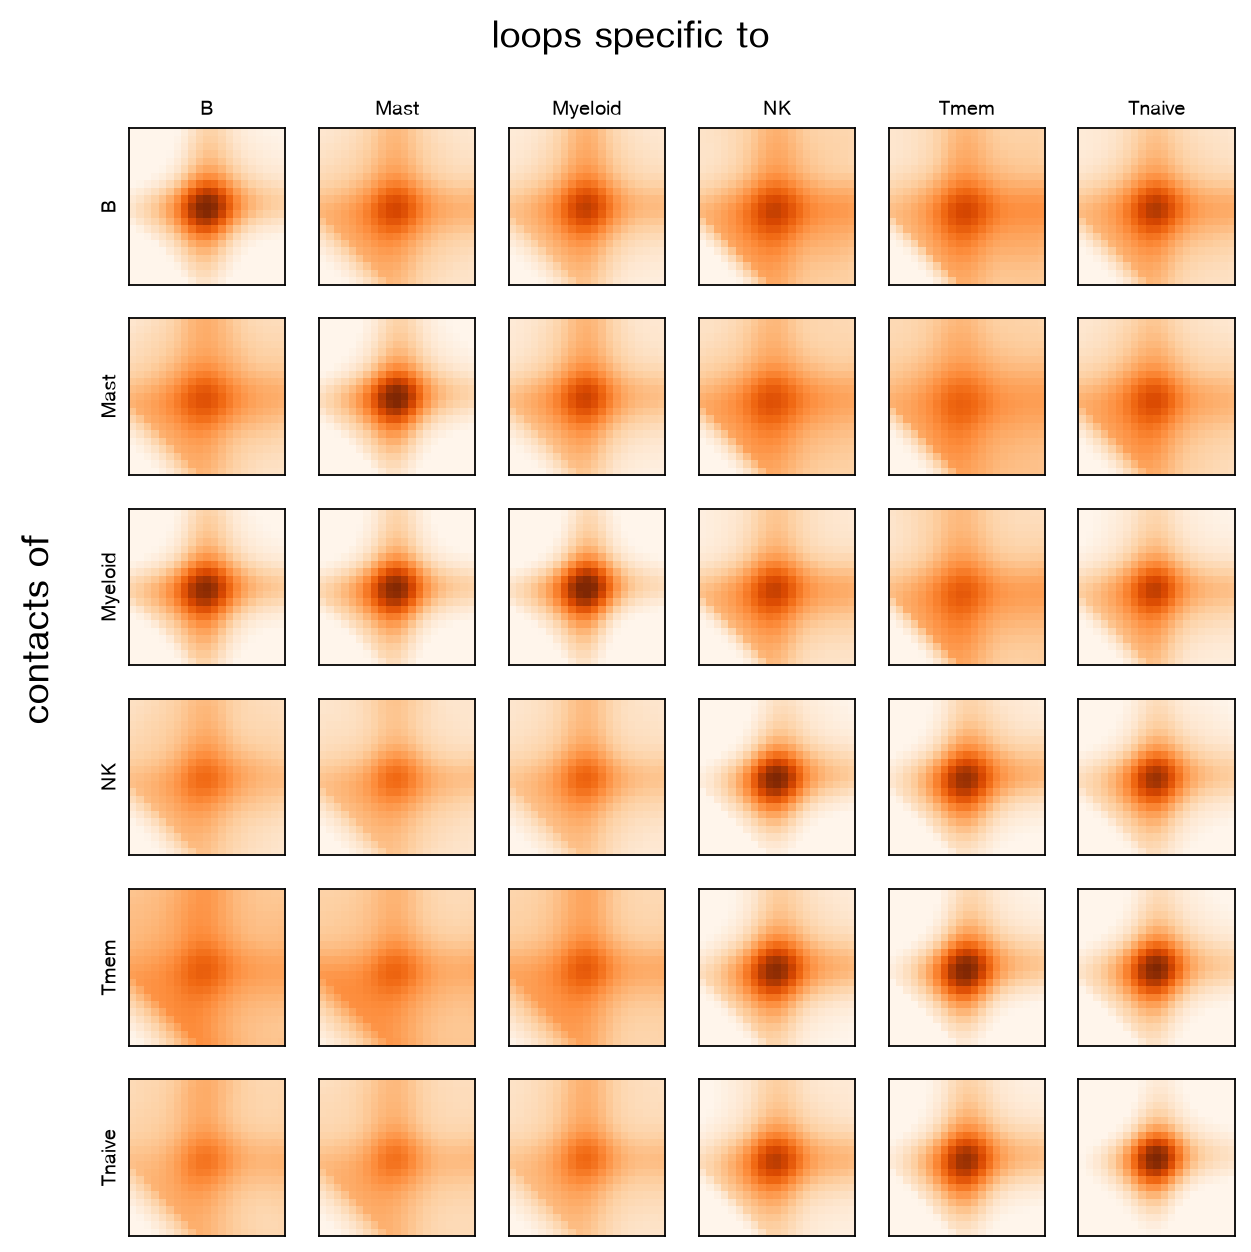

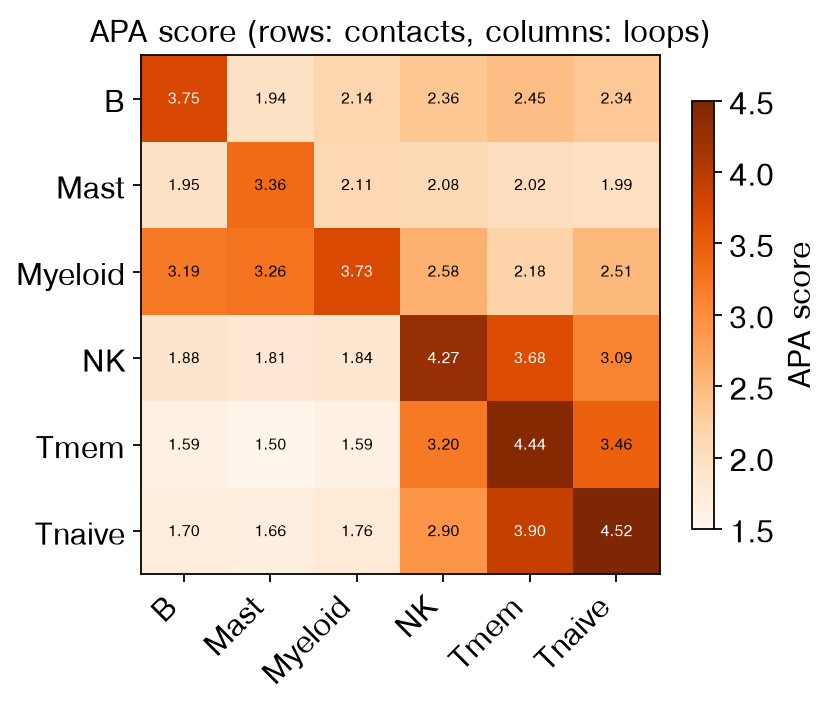

In [7]:
spec = hic.specific_loops(q, t_)
print(spec.sum().rename('specific loops').to_frame().T.to_string())
sets = {t: dl.loc[spec[t]] for t in TYPES}
APA = OUT / 'apa.npz'
if APA.exists():
    z = np.load(APA)
    apa = {(a, b): z[f'{a}|{b}'] for a in TYPES for b in TYPES}
else:
    apa = {}
    for a in TYPES:                                   # contacts of type a
        res = hic.loop_apa(f'{PREFIX[a]}.Q.cool', sets, chromosomes=CHROMS)
        for b in TYPES:                               # loops specific to type b
            apa[(a, b)] = res[b]
    np.savez(APA, **{f'{a}|{b}': v for (a, b), v in apa.items()})

fig, axes = plt.subplots(6, 6, figsize=(8, 8))
for i, a in enumerate(TYPES):
    for j, b in enumerate(TYPES):
        ax = axes[i, j]
        ax.imshow(apa[(a, b)], cmap='Oranges', vmin=0.3, vmax=0.75)
        ax.set_xticks([]); ax.set_yticks([])
        if i == 0: ax.set_title(b, fontsize=9)
        if j == 0: ax.set_ylabel(a, fontsize=9)
fig.supylabel('contacts of'); fig.suptitle('loops specific to')
plt.tight_layout(); plt.show()

score = pd.DataFrame({b: {a: apa[(a, b)][10, 10] / apa[(a, b)][-5:, :5].mean() for a in TYPES} for b in TYPES})
fig, ax, img = epi.pl.plot_correlation_heatmap(score, cmap='Oranges', vmin=1.5, vmax=4.5, figsize=(5.2, 4.4),
                                               annot_fontsize=7, title='APA score (rows: contacts, columns: loops)')
fig.axes[-1].set_ylabel('APA score')
plt.show()

Each type's specific loops stand out most in that type's own contacts: in every
column the APA score is highest on the diagonal (3.4-4.5, against 1.5-3.9
elsewhere). The lymphoid types share part of their loops: memory-T-specific
loops are also strong in naive T and NK cells (3.9 and 3.7), and NK-specific
loops in memory T cells (3.2). Myeloid contacts show the mast-specific loops
almost as strongly as mast cells themselves (3.3 against 3.4).

## 8 · An example: a B-cell loop at MS4A1

MS4A1 encodes CD20, the classic B-cell surface marker. Several B-specific
loops are anchored at it; we show the strongest (highest T in B cells) with
each type's T around it: red pixels contact each other more than their
neighbourhood, and loops appear as red dots.

  └─ Reading GTF file from data/gencode_hg38/gencode.v30.annotation.gtf...


  └─ GTF file read successfully
6 B-specific loops at MS4A1; strongest chr11:60,360,000-60,480,000 (110 kb)
T at the loop: {'B': 0.41, 'Mast': 0.19, 'Myeloid': 0.31, 'NK': 0.22, 'Tmem': 0.21, 'Tnaive': 0.15}


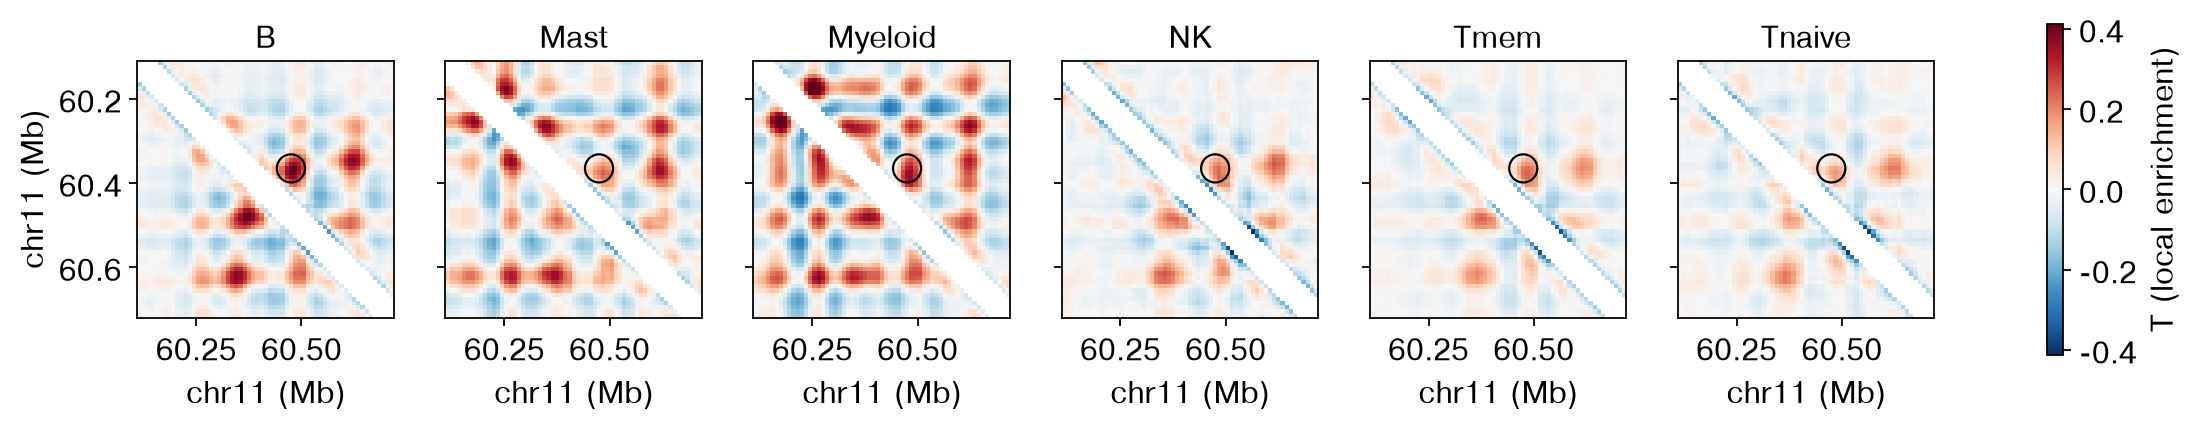

In [8]:
gtf = epi.io.read_gtf(GTF, required_attrs=('gene_id', 'gene_name', 'gene_type'), feature_whitelist=['gene'],
                      keep_attribute=False)
gene = gtf[gtf['gene_name'] == 'MS4A1'].iloc[0]
near = lambda pos: (pos >= gene['start'] - 20_000) & (pos <= gene['end'] + 20_000)
cand = dl.loc[spec['B'] & (dl['chrom1'] == gene['seqname']) & (near(dl['start1']) | near(dl['start2']))]
best = cand.loc[t_.loc[cand.index, 'B'].idxmax()]
c, x, y = best['chrom1'], int(best['start1']), int(best['start2'])
print(f"{len(cand)} B-specific loops at MS4A1; strongest {c}:{x:,}-{y + 10_000:,} ({(y - x) / 1e3:.0f} kb)")
print('T at the loop:', t_.loc[best.name].round(2).to_dict())

lo, hi = x - 250_000, y + 250_000
mats = {t: cooler.Cooler(f'{PREFIX[t]}.T.cool').matrix(balance=False).fetch(f'{c}:{lo}-{hi}') for t in TYPES}
n = len(next(iter(mats.values())))
ii, jj = np.indices((n, n))
near_diag = np.abs(ii - jj) < 5                      # the first 50 kb carry no loop signal
v = max(np.nanpercentile(np.abs(m[~near_diag]), 99.5) for m in mats.values())
fig, axes = plt.subplots(1, 6, figsize=(18, 3.4), sharey=True)
axes[0].set_ylabel(f'{c} (Mb)')
for ax, t in zip(axes, TYPES):
    m = mats[t].astype(float)
    m[near_diag] = np.nan
    im = ax.imshow(m, cmap='RdBu_r', vmin=-v, vmax=v, extent=(lo / 1e6, hi / 1e6, hi / 1e6, lo / 1e6))
    ax.scatter([y / 1e6 + 0.005], [x / 1e6 + 0.005], s=160, facecolors='none', edgecolors='k', lw=1)
    ax.set_title(t); ax.set_xlabel(f'{c} (Mb)')
fig.colorbar(im, ax=axes, shrink=0.8, label='T (local enrichment)')
plt.show()

The loop joins MS4A1 to a site about 110 kb away. It is a clear dot in B cells
(T = 0.41) and much weaker in the other types (0.15-0.31, highest in myeloid
cells). The T maps also show loops shared by several types nearby.

## 9 · Differential loops and gene expression

Do the loops that differ between the types sit at genes that are expressed
differently? Following the atlas (Fig. 4F, G), we take blood single-cell
RNA-seq, find the genes that differ between the types, and pair each
differential loop with the differentially expressed genes (DEGs) whose
transcription start site (TSS, ± 2 kb) lies in one of its two anchors.

**RNA data.** Hao *et al.* 2021 (PBMC CITE-seq, 161,764 cells, 8 donors at 3
time points; `Blood_Hao2021.h5ad`). Its cell types (`celltype.l2`) are mapped
to the HCEA types as in the atlas's RNA summary. PBMC have no mast cells, so
this part uses the five other types.

In [9]:
import anndata as ad
from scipy.sparse import csr_matrix

RNA = DATA / 'scRNA_blood/Hao2021/Blood_Hao2021.h5ad'
L2_TO_TYPE = {
    'Myeloid': ['CD14 Mono', 'CD16 Mono', 'ASDC', 'cDC1', 'cDC2', 'pDC'],
    'B': ['B intermediate', 'B memory', 'B naive', 'Plasmablast'],
    'Tnaive': ['CD4 Naive', 'CD8 Naive'],
    'Tmem': ['CD4 CTL', 'CD4 Proliferating', 'CD4 TCM', 'CD4 TEM', 'CD8 Proliferating', 'CD8 TCM',
             'CD8 TEM', 'Treg', 'dnT', 'gdT', 'MAIT'],
    'NK': ['NK', 'NK Proliferating', 'NK_CD56bright', 'ILC'],
}
RNA_TYPES = [t for t in TYPES if t in L2_TO_TYPE]          # B, Myeloid, NK, Tmem, Tnaive
PB = OUT / 'rna_pseudobulk.parquet'
if PB.exists():
    pb = pd.read_parquet(PB)
else:
    rna = ad.read_h5ad(RNA)
    l2 = {v: t for t, vs in L2_TO_TYPE.items() for v in vs}
    group = (rna.obs['donor_id'].astype(str) + '|' + rna.obs['celltype.l2'].map(l2).astype(str)).to_numpy()
    keep = ~pd.Series(group).str.endswith('|nan').to_numpy()
    labels, idx = np.unique(group[keep], return_inverse=True)
    onehot = csr_matrix((np.ones(keep.sum()), (idx, np.arange(keep.sum()))), shape=(len(labels), keep.sum()))
    counts = onehot @ csr_matrix(rna.raw.X)[np.flatnonzero(keep)]            # donor x type pseudobulk
    pb = pd.DataFrame(counts.toarray(), index=labels, columns=rna.raw.var_names.astype(str))
    pb['n_cells'] = np.bincount(idx)
    pb.to_parquet(PB)
n_cells = pb.pop('n_cells')
pb = pb.loc[n_cells > 100]                                    # as the atlas: groups of > 100 cells
design = pd.DataFrame([i.split('|') for i in pb.index], index=pb.index, columns=['donor_id', 'celltype'])
print(f'{len(pb)} pseudobulk samples (donor x type), {pb.shape[1]:,} genes')
pd.crosstab(design['donor_id'], design['celltype'])

40 pseudobulk samples (donor x type), 20,525 genes


celltype,B,Myeloid,NK,Tmem,Tnaive
donor_id,,,,,
P1,1,1,1,1,1
P2,1,1,1,1,1
P3,1,1,1,1,1
P4,1,1,1,1,1
P5,1,1,1,1,1
P6,1,1,1,1,1
P7,1,1,1,1,1
P8,1,1,1,1,1


Every pair of types is compared with DESeq2 (`epi.tl.differential_peaks`,
which runs PyDESeq2 on any count matrix), with the donor in the design so
that donors act as replicates. As in the atlas, a gene is a DEG when it
differs more than 4-fold (|log2 fold change| > 2) at FDR < 1e-10 in at least
one pair.

In [10]:
from itertools import combinations
from statsmodels.stats.multitest import multipletests

DEG = OUT / 'rna_deg.parquet'
if DEG.exists():
    deg = pd.read_parquet(DEG)
else:
    rows = []
    for a, b in combinations(RNA_TYPES, 2):
        r = epi.tl.differential_peaks(counts=pb, metadata=design, design='~donor_id + celltype',
                                      contrast=('celltype', a, b), n_cpus=NPROC)
        r['fdr'] = multipletests(r['pvalue'].fillna(1), method='fdr_bh')[1]
        rows.append(r.assign(a=a, b=b))
    deg = pd.concat(rows).rename_axis('gene_id').reset_index()
    deg.to_parquet(DEG)
sig = deg[(deg['log2FoldChange'].abs() > 2) & (deg['fdr'] < 1e-10)]
deg_genes = pd.Index(sig['gene_id'].unique())
print(f'{len(deg_genes):,} DEGs; per pair:')
sig.groupby(['a', 'b']).size().unstack(fill_value=0)

5,968 DEGs; per pair:


b,Myeloid,NK,Tmem,Tnaive
a,,,,
B,2969,1569,1542,1481
Myeloid,0,2902,3410,3665
NK,0,0,623,1357
Tmem,0,0,0,471


Next, each differential loop is paired with the DEGs whose TSS (± 2 kb) falls
in its 10 kb anchor bins. For every pair we z-score the loop's Q across the
five types and the gene's expression (counts per million) across the
pseudobulk samples, then cluster the pairs on both together (k-means), as in
the atlas.

5,524 differential loops at 1,002 DEGs (6,363 pairs)


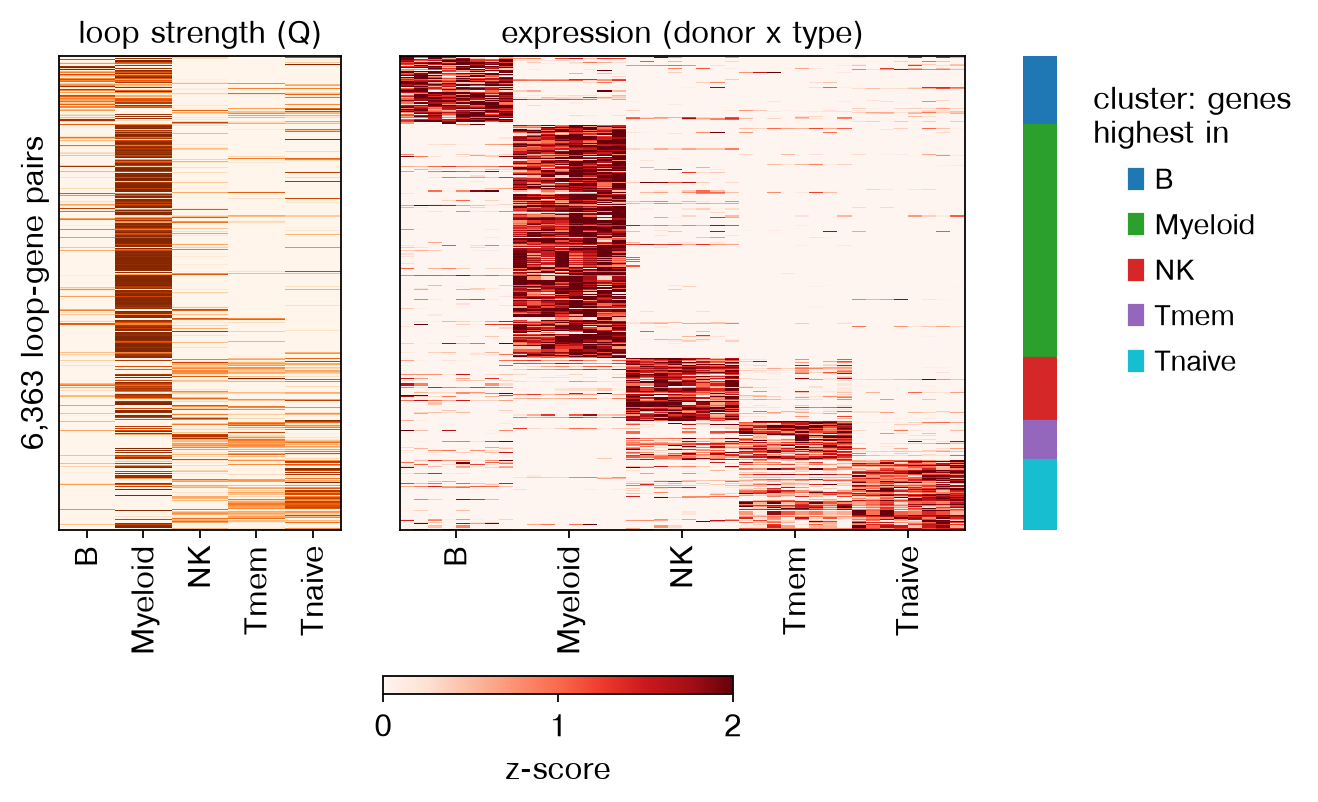

In [11]:
from sklearn.cluster import KMeans

genes = gtf.copy()                                   # GENCODE genes, read in section 8
genes['gene_id'] = genes['gene_id'].str.split('.').str[0]
genes = genes[genes['gene_id'].isin(deg_genes) & genes['seqname'].isin(CHROMS)]
tss = np.where(genes['strand'] == '+', genes['start'], genes['end'])
RES = 10_000
bin2gene = {}
for c, t0, g in zip(genes['seqname'], tss, genes['gene_id']):
    for b in range((t0 - 2000) // RES, (t0 + 2000) // RES + 1):     # bins within 2 kb of the TSS
        bin2gene.setdefault((c, b), []).append(g)

pairs = []
for i, (c, x, y) in enumerate(zip(dl['chrom1'], dl['start1'] // RES, dl['start2'] // RES)):
    for g in sorted(set(bin2gene.get((c, x), []) + bin2gene.get((c, y), []))):
        pairs.append((i, g))
pairs = pd.DataFrame(pairs, columns=['loop', 'gene_id'])
print(f"{pairs['loop'].nunique():,} differential loops at {pairs['gene_id'].nunique():,} DEGs ({len(pairs):,} pairs)")

cpm = pb / pb.sum(axis=1).to_numpy()[:, None] * 1e6
order = design.sort_values(['celltype', 'donor_id']).index
z_loop = zscore(q.loc[pairs['loop'], RNA_TYPES].to_numpy(), axis=1)
z_rna = zscore(cpm.loc[order, pairs['gene_id']].to_numpy().T, axis=1)
K = 5
km = KMeans(n_clusters=K, n_init=10, random_state=0).fit(np.nan_to_num(np.hstack([z_loop, z_rna])))
# label and order clusters by the type where their genes are most expressed
rna_type = design.loc[order, 'celltype'].to_numpy()
by_type = pd.DataFrame({t: z_rna[:, rna_type == t].mean(axis=1) for t in RNA_TYPES})
peak = by_type.groupby(km.labels_).mean().idxmax(axis=1)
peak = peak.iloc[np.argsort([RNA_TYPES.index(t) for t in peak], kind='stable')]
rows_ = np.concatenate([np.flatnonzero(km.labels_ == k) for k in peak.index])

fig, axes = plt.subplots(1, 3, figsize=(8, 6), sharey=True, gridspec_kw={'width_ratios': [5, 10, 0.6]})
axes[0].imshow(z_loop[rows_], cmap='Oranges', vmin=0, vmax=2, aspect='auto', interpolation='none')
axes[0].set_xticks(range(len(RNA_TYPES))); axes[0].set_xticklabels(RNA_TYPES, rotation=90)
axes[0].set_title('loop strength (Q)'); axes[0].set_ylabel(f'{len(pairs):,} loop-gene pairs'); axes[0].set_yticks([])
im = axes[1].imshow(z_rna[rows_], cmap='Reds', vmin=0, vmax=2, aspect='auto', interpolation='none')
centers = design.loc[order, 'celltype'].reset_index(drop=True).reset_index().groupby('celltype')['index'].mean()
axes[1].set_xticks(centers.loc[RNA_TYPES]); axes[1].set_xticklabels(RNA_TYPES, rotation=90)
axes[1].set_title('expression (donor x type)')
bounds = np.r_[0, np.cumsum([np.sum(km.labels_ == k) for k in peak.index])]
for k in range(K):
    axes[2].add_patch(plt.Rectangle((0, bounds[k] - 0.5), 1, bounds[k + 1] - bounds[k],
                                    color=COLORS[peak.iloc[k]]))
axes[2].set_xlim(0, 1); axes[2].axis('off')
axes[2].legend(handles=[plt.Rectangle((0, 0), 1, 1, color=COLORS[t]) for t in RNA_TYPES], labels=RNA_TYPES,
               title='cluster: genes\nhighest in', loc='upper left', bbox_to_anchor=(1.3, 1), frameon=False)
fig.colorbar(im, ax=axes, shrink=0.35, label='z-score', location='bottom', pad=0.2)
plt.show()

Are a loop's strength and its gene's expression higher in the same types?
For every pair we correlate the loop's Q with the gene's mean expression
across the five types, and compare with pairs whose genes were shuffled.

median r: loop-gene pairs 0.79, shuffled 0.08; r > 0.5: 69% vs 37%


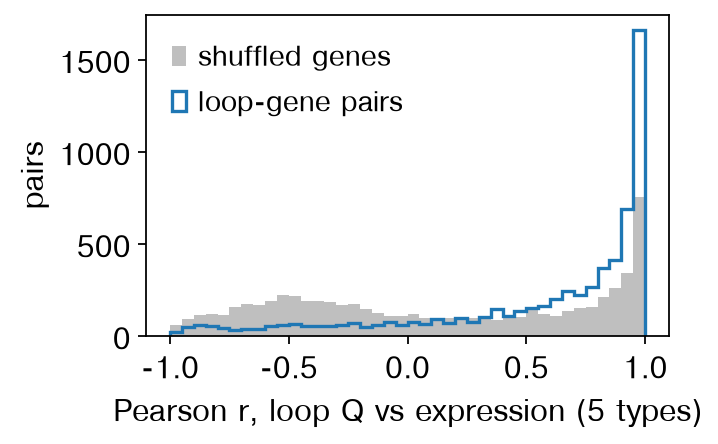

In [12]:
mean_cpm = cpm.groupby(design['celltype']).mean().loc[RNA_TYPES]
a = q.loc[pairs['loop'], RNA_TYPES].to_numpy()
b = mean_cpm[pairs['gene_id']].to_numpy().T
def rowcorr(x, y):
    x, y = zscore(x, axis=1), zscore(y, axis=1)
    return np.nanmean(x * y, axis=1)
r_real = rowcorr(a, b)
r_null = rowcorr(a, b[np.random.default_rng(0).permutation(len(b))])
print(f'median r: loop-gene pairs {np.nanmedian(r_real):.2f}, shuffled {np.nanmedian(r_null):.2f}; '
      f'r > 0.5: {np.nanmean(r_real > 0.5):.0%} vs {np.nanmean(r_null > 0.5):.0%}')
fig, ax = plt.subplots(figsize=(4.5, 3))
ax.hist(r_null, bins=40, range=(-1, 1), color='0.75', label='shuffled genes')
ax.hist(r_real, bins=40, range=(-1, 1), histtype='step', color=COLORS['B'], lw=1.5, label='loop-gene pairs')
ax.set_xlabel('Pearson r, loop Q vs expression (5 types)'); ax.set_ylabel('pairs'); ax.legend(frameon=False)
plt.tight_layout(); plt.show()

Loop strength and gene expression go together. The k-means clusters are
blocks of genes expressed in one type (bar on the right), and their loops are
strongest in the same type; myeloid genes form the largest block. Myeloid
loops are strong in most rows because Q is not normalised between types (as
in the atlas); the correlation below is computed per pair and is not affected
by that. Across all pairs the
median correlation between a loop's Q and its gene's expression over the five
types is 0.79, against 0.08 when the genes are shuffled, and 69 % of pairs
have r > 0.5 (37 % shuffled).

### Loops around one gene

The atlas shows the differential loops around a gene on each type's contact
map (Fig. 4F, *OXTR* in breast). Here: among protein-coding DEGs expressed in
at least one type (mean ≥ 50 counts per million), the one with the most
differential loops, with each type's imputed contacts (Q) over 2 Mb around its
TSS and the differential loops marked.

THBS1: 42 differential loops; mean CPM by type: {'B': 5.0, 'Myeloid': 248.0, 'NK': 10.0, 'Tmem': 6.0, 'Tnaive': 5.0}


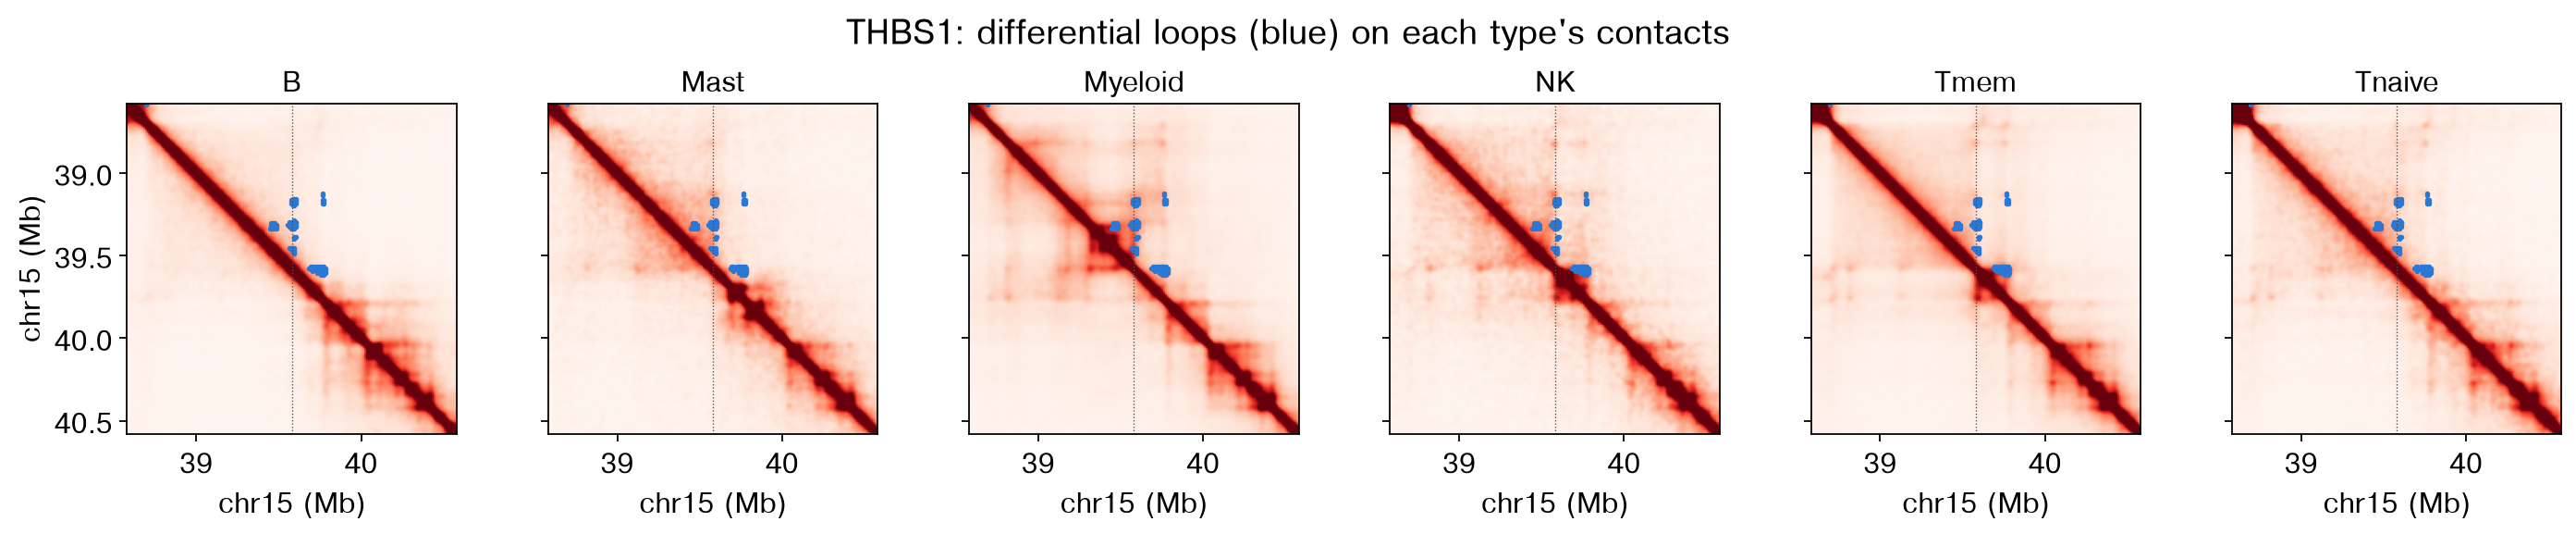

In [13]:
expressed = mean_cpm.columns[mean_cpm.max() >= 50]          # expressed in at least one type
coding = genes.loc[genes['gene_type'] == 'protein_coding', 'gene_id']
cand = pairs[pairs['gene_id'].isin(expressed) & pairs['gene_id'].isin(coding)]
top = cand['gene_id'].value_counts().index[0]
gname = genes.loc[genes['gene_id'] == top, 'gene_name'].iloc[0]
g = genes[genes['gene_id'] == top].iloc[0]
c, t0 = g['seqname'], int(g['start'] if g['strand'] == '+' else g['end'])
lo, hi = (t0 - 1_000_000) // RES * RES, (t0 + 1_000_000) // RES * RES
print(f"{gname}: {cand['gene_id'].value_counts().iloc[0]} differential loops; mean CPM by type:",
      mean_cpm[top].round(0).to_dict())
d = dl[(dl['chrom1'] == c) & (dl['start1'] >= lo) & (dl['start2'] < hi)]
fig, axes = plt.subplots(1, len(TYPES), figsize=(18, 3.4), sharey=True)
mats = {t: cooler.Cooler(f'{PREFIX[t]}.Q.cool').matrix(balance=False).fetch(f'{c}:{lo}-{hi}') for t in TYPES}
vmax = np.nanpercentile(np.concatenate([np.triu(m, 3).ravel() for m in mats.values()]), 99)
for ax, t in zip(axes, TYPES):
    ax.imshow(mats[t], cmap='Reds', vmin=0, vmax=vmax, extent=(lo / 1e6, hi / 1e6, hi / 1e6, lo / 1e6))
    ax.scatter((d['start2'] + 5000) / 1e6, (d['start1'] + 5000) / 1e6, s=6, color='#2a78d6', lw=0)
    ax.axvline(t0 / 1e6, color='0.3', lw=0.6, ls=':')
    ax.set_title(t); ax.set_xlabel(f'{c} (Mb)')
axes[0].set_ylabel(f'{c} (Mb)')
fig.suptitle(f'{gname}: differential loops (blue) on each type\'s contacts')
plt.tight_layout(); plt.show()

## Summary

| Step | epione |
|---|---|
| loops per group | `call_loops` (scHiCluster, from imputed `.cool` cells) |
| one loop set | `merge_loops` |
| ANOVA across groups | `loop_anova` |
| differential loops | `loop_values`, `differential_loops` |
| type-specific loops, APA | `specific_loops`, `loop_apa` |
| loops and gene expression | pseudobulk RNA, `epi.tl.differential_peaks` (PyDESeq2), loop-TSS pairs |

`loop_anova`, `merge_loops`, `loop_values` and the FDR reproduce the atlas's
differential-loop analysis of all 35 major types
(`tests/parity/schicluster_loop`). To call loops on your own cells, impute
them at 10 kb (`impute_cells(resolution=10_000, pad=2, window_size=30_000_000,
step_size=10_000_000, output_dist=5_050_000)`, which writes one `.cool` per
cell) and run `call_loops(adata, groupby=..., out_dir=..., black_list=...)`;
its output prefixes go straight into `loop_anova` and `merge_loops`.